# Recommendation System Development Using Collaborative Filtering

**Techniques:** User-Based Collaborative Filtering (UBCF), Item-Based Collaborative Filtering (IBCF), SGD Matrix Factorization, and Truncated SVD  
**Mapped CO:** CO4

## Aim
Develop recommendation systems using collaborative filtering techniques and visualize recommendation outcomes for performance evaluation.

## Objectives
- Understand user–item rating data and collaborative filtering.
- Implement UBCF and IBCF using cosine similarity.
- Implement latent-factor Matrix Factorization and Singular Value Decomposition (SVD).
- Predict unseen ratings and recommend items to users.
- Visualize ratings, similarities, predictions, and model performance.

## Dataset
This notebook creates a **reproducible synthetic movie-rating dataset**. Each row contains a user, a movie, and a rating from 1 to 5. The dataset is generated from hidden user/movie preference patterns, then made sparse to imitate a real recommendation platform. No external download is required.

> The dataset is synthetic and is intended for learning and experimentation. For a larger real-world experiment, the same workflow can be adapted to MovieLens.

## 1. Collaborative filtering: short theory

A user–item matrix contains ratings supplied by users for items. Most real-world entries are missing because each user interacts with only a small fraction of all available items.

- **UBCF:** Find users whose rating patterns resemble the target user's pattern. Use ratings from similar users to estimate the target user's missing rating.
- **IBCF:** Find items whose rating patterns resemble the target item. Use the target user's ratings for similar items to estimate a missing rating.
- **Matrix Factorization (MF):** Learn low-dimensional user and item vectors. Their dot product, together with user/item biases, estimates a rating.
- **SVD:** A matrix factorization technique. Here, `TruncatedSVD` is applied to a user-mean-centered rating matrix to obtain a low-rank approximation.

### Prediction intuition

For user-based CF, a common mean-centered prediction is:

\[
\hat r_{ui}=\bar r_u +
\frac{\sum_{v\in N_k(u)} s(u,v)(r_{vi}-\bar r_v)}
{\sum_{v\in N_k(u)} |s(u,v)|}
\]

For item-based CF, use similar items already rated by the target user:

\[
\hat r_{ui}=\bar r_u +
\frac{\sum_{j\in N_k(i)} s(i,j)(r_{uj}-\bar r_u)}
{\sum_{j\in N_k(i)} |s(i,j)|}
\]

The latent-factor model predicts:

\[
\hat r_{ui}=\mu+b_u+b_i+p_u^Tq_i
\]

where \(\mu\) is the global mean, \(b_u,b_i\) are biases, and \(p_u,q_i\) are learned latent vectors.

**Evaluation:** Ratings are numerical values, so this notebook uses **RMSE** and **MAE**, not classification accuracy. Lower values indicate better rating predictions.

## 2. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import mean_squared_error, mean_absolute_error

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_rows", 20)
pd.set_option("display.max_columns", 20)

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Create the sample user–item rating dataset

In [2]:
# Movie titles are used instead of numeric IDs to make the output readable.
movie_titles = [
    "Action Force", "Space Journey", "Love in Paris", "The Detective",
    "Funny Neighbours", "Wild Planet", "The Last Battle", "Quiet Summer",
    "Code Breaker", "Ocean Mystery", "Campus Days", "Robot Future",
    "Mountain Story", "Dark Secret", "Music Nights"
]
user_ids = [f"U{i:02d}" for i in range(1, 25)]

rng = np.random.default_rng(RANDOM_STATE)
n_users, n_items, n_factors_true = len(user_ids), len(movie_titles), 3

# Hidden preference vectors are used only to generate a realistic teaching dataset.
true_user_factors = rng.normal(0, 0.65, size=(n_users, n_factors_true))
true_item_factors = rng.normal(0, 0.65, size=(n_items, n_factors_true))
user_bias = rng.normal(0, 0.25, size=n_users)
item_bias = rng.normal(0, 0.25, size=n_items)

all_rows = []
for u_idx, user in enumerate(user_ids):
    for i_idx, item in enumerate(movie_titles):
        latent_score = true_user_factors[u_idx] @ true_item_factors[i_idx]
        raw_rating = 3.3 + 1.05 * latent_score + user_bias[u_idx] + item_bias[i_idx]
        raw_rating += rng.normal(0, 0.45)
        rating = float(np.clip(np.round(raw_rating), 1, 5))

        # Keep approximately 70% of interactions, leaving the matrix sparse.
        if rng.random() < 0.70:
            all_rows.append((user, item, rating))

ratings = pd.DataFrame(all_rows, columns=["User", "Item", "Rating"])
ratings = ratings.sort_values(["User", "Item"]).reset_index(drop=True)

print(f"Dataset loaded/generated successfully: {len(ratings)} ratings")
print(f"Users: {ratings['User'].nunique()} | Movies: {ratings['Item'].nunique()}")
print(f"Rating density: {len(ratings) / (n_users * n_items):.1%}")
display(ratings.head(10))

Dataset loaded/generated successfully: 254 ratings
Users: 24 | Movies: 15
Rating density: 70.6%


,User,Item,Rating
0,U01,Action Force,3.0
1,U01,Code Breaker,4.0
2,U01,Dark Secret,3.0
3,U01,Funny Neighbours,3.0
4,U01,Love in Paris,3.0
5,U01,Quiet Summer,4.0
6,U01,Robot Future,3.0
7,U01,Space Journey,3.0
8,U01,The Last Battle,3.0
9,U01,Wild Planet,4.0


## 4. Explore the dataset

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 254 entries, 0 to 253
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   User    254 non-null    str    
 1   Item    254 non-null    str    
 2   Rating  254 non-null    float64
dtypes: float64(1), str(2)
memory usage: 6.1 KB
None

Rating statistics:


,Rating
count,254.000000
mean,3.303150
std,0.784377
min,1.000000
25%,3.000000
50%,3.000000
75%,4.000000
max,5.000000



Number of ratings per user:


User,U01,U02,U03,U04,U05,U06,U07,U08,U09,U10,...,U15,U16,U17,U18,U19,U20,U21,U22,U23,U24
Rating Count,10,11,9,12,13,10,10,10,13,7,...,7,7,11,11,12,13,11,12,10,11


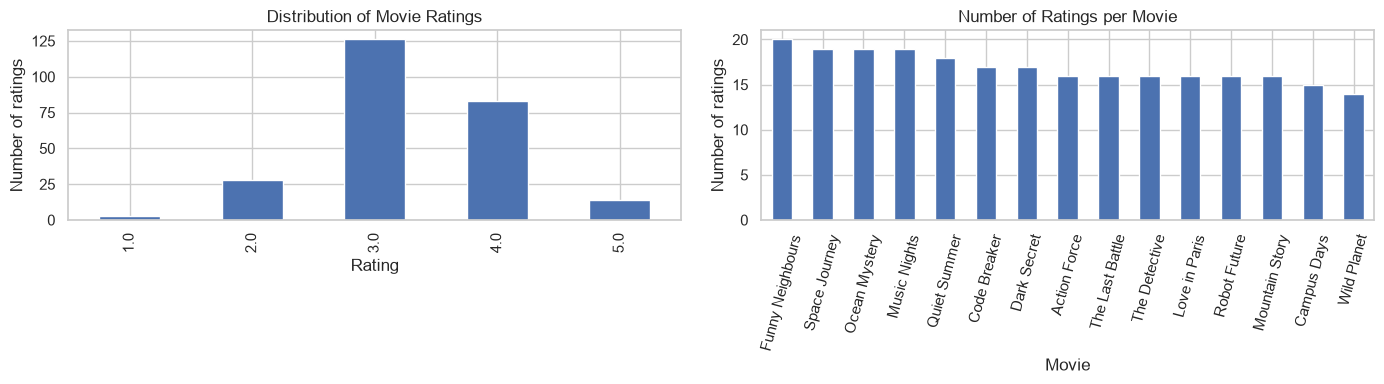

In [3]:
print("Dataset information:")
print(ratings.info())
print("\nRating statistics:")
display(ratings["Rating"].describe().to_frame())

print("\nNumber of ratings per user:")
display(ratings.groupby("User").size().rename("Rating Count").to_frame().T)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
ratings["Rating"].value_counts().sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_title("Distribution of Movie Ratings")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Number of ratings")

item_counts = ratings["Item"].value_counts().reindex(movie_titles)
item_counts.sort_values(ascending=False).plot(kind="bar", ax=axes[1])
axes[1].set_title("Number of Ratings per Movie")
axes[1].set_xlabel("Movie")
axes[1].set_ylabel("Number of ratings")
axes[1].tick_params(axis="x", rotation=75)
plt.tight_layout()
plt.show()

## 5. Construct the user–item matrix

User-item matrix created successfully.
Shape: (24, 15)


Item,Action Force,Space Journey,Love in Paris,The Detective,Funny Neighbours,Wild Planet,The Last Battle,Quiet Summer,Code Breaker,Ocean Mystery,Campus Days,Robot Future,Mountain Story,Dark Secret,Music Nights
User,,,,,,,,,,,,,,,
U01,3.0,3.0,3.0,NaN,3.0,4.0,3.0,4.0,4.0,NaN,NaN,3.0,NaN,3.0,NaN
U02,NaN,3.0,5.0,4.0,2.0,NaN,4.0,5.0,4.0,2.0,3.0,NaN,NaN,5.0,5.0
U03,3.0,NaN,NaN,3.0,3.0,3.0,4.0,NaN,NaN,3.0,NaN,2.0,NaN,4.0,3.0
U04,3.0,3.0,NaN,4.0,3.0,4.0,NaN,2.0,3.0,4.0,3.0,2.0,2.0,NaN,3.0
U05,3.0,3.0,3.0,3.0,4.0,4.0,NaN,NaN,3.0,3.0,3.0,3.0,2.0,3.0,3.0


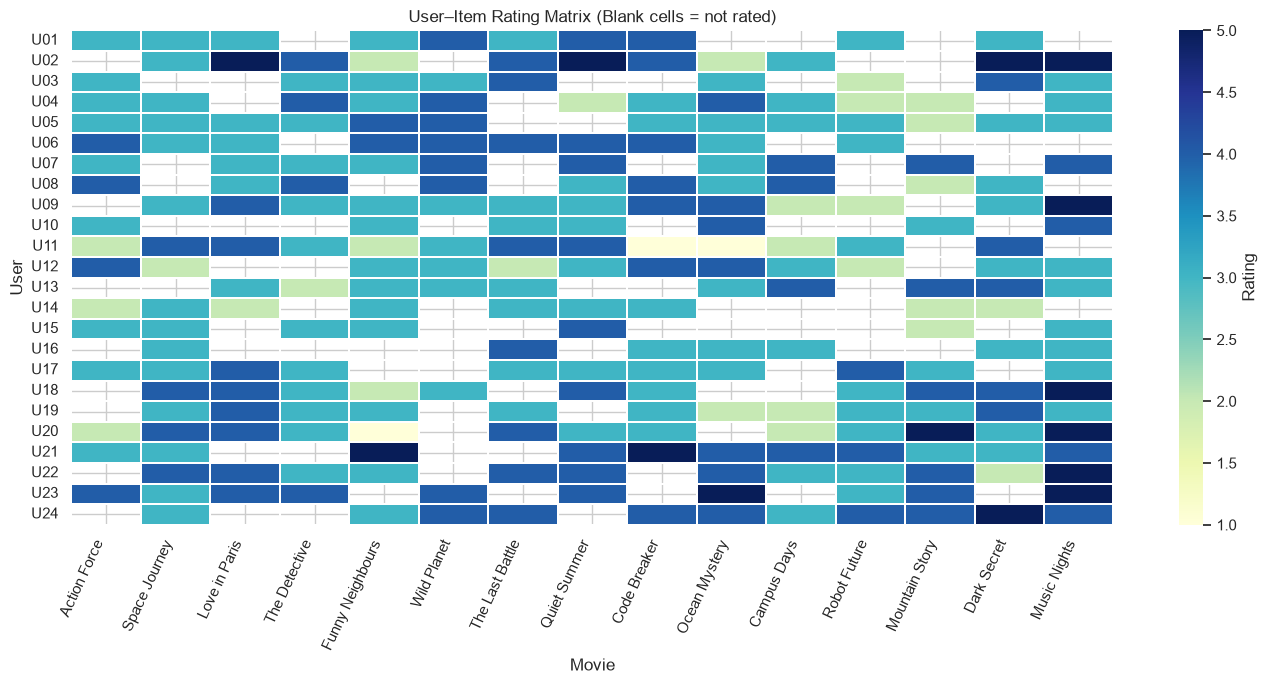

In [4]:
user_list = sorted(ratings["User"].unique())
item_list = movie_titles  # Keep a consistent movie order in every table/plot.

# NaN means that the user has not rated that movie.
full_matrix = ratings.pivot(index="User", columns="Item", values="Rating")
full_matrix = full_matrix.reindex(index=user_list, columns=item_list)

print("User-item matrix created successfully.")
print("Shape:", full_matrix.shape)
display(full_matrix.head())

plt.figure(figsize=(14, 7))
sns.heatmap(full_matrix, cmap="YlGnBu", vmin=1, vmax=5, linewidths=0.25,
            linecolor="white", cbar_kws={"label": "Rating"})
plt.title("User–Item Rating Matrix (Blank cells = not rated)")
plt.xlabel("Movie")
plt.ylabel("User")
plt.xticks(rotation=65, ha="right")
plt.tight_layout()
plt.show()

## 6. Split ratings into training and testing sets

We hold out approximately 20% of each user's ratings for testing. The models learn from the training set only; the held-out ratings are used to evaluate how well each method predicts unseen interactions.

In [5]:
rng_split = np.random.default_rng(RANDOM_STATE)
train_parts, test_parts = [], []

for user, group in ratings.groupby("User"):
    indices = group.index.to_numpy().copy()
    rng_split.shuffle(indices)
    n_test = max(1, int(round(0.20 * len(indices))))
    test_idx = indices[:n_test]
    train_idx = indices[n_test:]
    train_parts.append(ratings.loc[train_idx])
    test_parts.append(ratings.loc[test_idx])

train_df = pd.concat(train_parts).sort_index().reset_index(drop=True)
test_df = pd.concat(test_parts).sort_index().reset_index(drop=True)

# Reindex to the complete user and item universe. Missing training ratings are 0 internally.
R_train = (train_df.pivot(index="User", columns="Item", values="Rating")
           .reindex(index=user_list, columns=item_list).fillna(0.0))

print(f"Training ratings: {len(train_df)}")
print(f"Testing ratings:  {len(test_df)}")
print("Training matrix shape:", R_train.shape)
print("Every user has at least one training rating:", bool((R_train > 0).sum(axis=1).ge(1).all()))
display(train_df.head())

Training ratings: 205
Testing ratings:  49
Training matrix shape: (24, 15)
Every user has at least one training rating: True


,User,Item,Rating
0,U01,Action Force,3.0
1,U01,Code Breaker,4.0
2,U01,Dark Secret,3.0
3,U01,Funny Neighbours,3.0
4,U01,Love in Paris,3.0


## 7. Calculate user and item similarities

User similarity matrix generated: (24, 24)
Item similarity matrix generated: (15, 15)


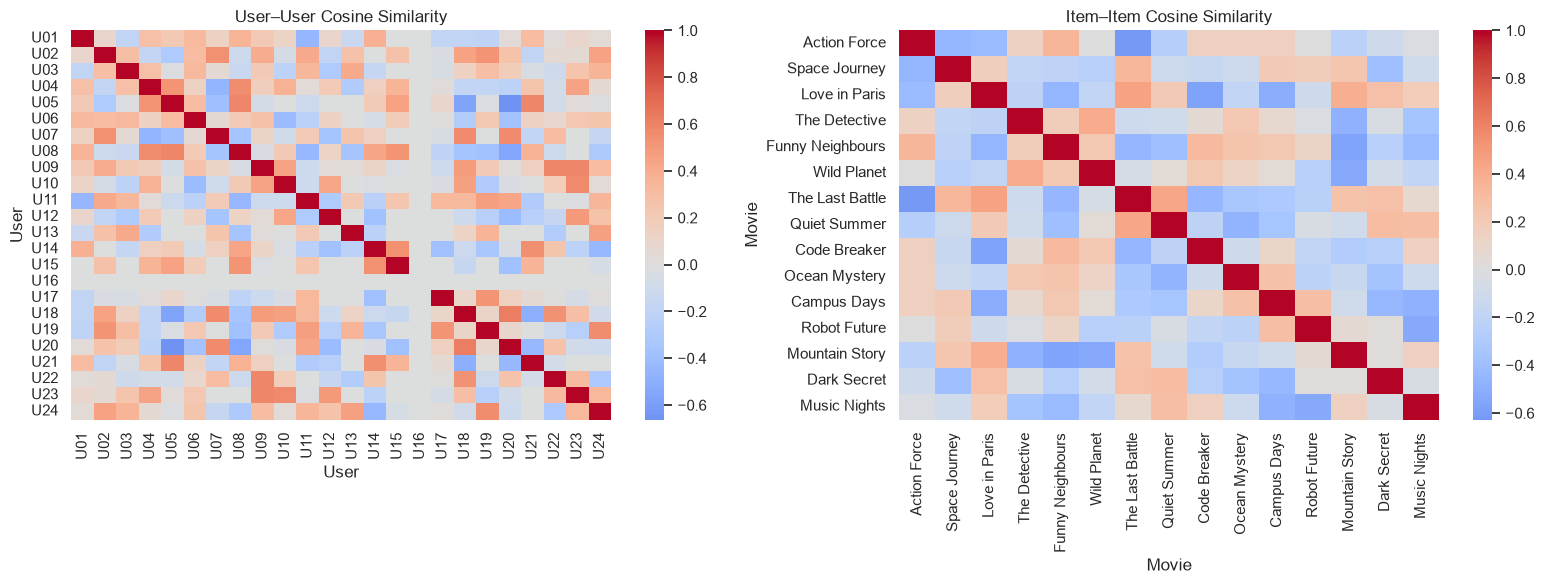

In [6]:
# Calculate each user's mean using observed training ratings only.
user_means = R_train.replace(0, np.nan).mean(axis=1).fillna(train_df["Rating"].mean())
item_means = R_train.replace(0, np.nan).mean(axis=0).fillna(train_df["Rating"].mean())
global_mean = float(train_df["Rating"].mean())

# Mean-center observed ratings. A zero represents a missing interaction in this representation.
centered_matrix = R_train.sub(user_means, axis=0).where(R_train > 0, 0.0)

# UBCF: similarity between rows (users).
user_similarity = pd.DataFrame(
    cosine_similarity(centered_matrix), index=user_list, columns=user_list
)

# IBCF: similarity between columns (movies).
item_similarity = pd.DataFrame(
    cosine_similarity(centered_matrix.T), index=item_list, columns=item_list
)

print("User similarity matrix generated:", user_similarity.shape)
print("Item similarity matrix generated:", item_similarity.shape)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(user_similarity, cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("User–User Cosine Similarity")
axes[0].set_xlabel("User")
axes[0].set_ylabel("User")

sns.heatmap(item_similarity, cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Item–Item Cosine Similarity")
axes[1].set_xlabel("Movie")
axes[1].set_ylabel("Movie")
plt.tight_layout()
plt.show()

## 8. User-Based Collaborative Filtering (UBCF)

For a target user/movie pair, UBCF selects the most similar users who have rated that movie. Their mean-centered ratings are combined using similarity-weighted averaging. If there are no useful neighbors, an item/global-mean fallback is used.

In [7]:
def predict_ubcf(user, item, k=5):
    """Predict one rating using the k most similar users who rated the item."""
    if user not in R_train.index or item not in R_train.columns:
        return global_mean

    target_user_mean = float(user_means.loc[user])
    rated_by = R_train[item]
    candidates = user_similarity[user].drop(index=user, errors="ignore")
    candidates = candidates[(rated_by.reindex(candidates.index) > 0) & (candidates > 0)]
    neighbors = candidates.sort_values(ascending=False).head(k)

    if neighbors.empty:
        return float(item_means.loc[item])

    neighbor_deviations = np.array([
        float(R_train.loc[neighbor, item] - user_means.loc[neighbor])
        for neighbor in neighbors.index
    ])
    weights = neighbors.to_numpy(dtype=float)
    prediction = target_user_mean + np.dot(weights, neighbor_deviations) / (np.abs(weights).sum() + 1e-12)
    return float(np.clip(prediction, 1, 5))


def recommend_ubcf(user, n=5, k=5):
    """Recommend the top-n movies that the user has not rated in the training set."""
    unseen = R_train.columns[R_train.loc[user] == 0]
    predictions = [(item, predict_ubcf(user, item, k=k)) for item in unseen]
    return pd.DataFrame(predictions, columns=["Item", "Predicted Rating"]).sort_values(
        "Predicted Rating", ascending=False
    ).head(n).reset_index(drop=True)

example_user = user_list[0]
print(f"Top UBCF recommendations for {example_user}:")
display(recommend_ubcf(example_user, n=5))

Top UBCF recommendations for U01:


,Item,Predicted Rating
0,Music Nights,3.615716
1,Quiet Summer,3.534962
2,The Detective,3.509901
3,Ocean Mystery,3.299399
4,Campus Days,3.244065


## 9. Item-Based Collaborative Filtering (IBCF)

IBCF finds movies similar to the movie being predicted. It uses the target user's ratings for the most similar movies and combines their mean-centered values.

In [8]:
def predict_ibcf(user, item, k=5):
    """Predict one rating using the k most similar items already rated by the user."""
    if user not in R_train.index or item not in R_train.columns:
        return global_mean

    user_ratings = R_train.loc[user]
    rated_items = user_ratings[user_ratings > 0].index
    rated_items = rated_items.drop(item, errors="ignore")

    if len(rated_items) == 0:
        return float(item_means.loc[item])

    similarities = item_similarity.loc[item, rated_items]
    similarities = similarities[similarities > 0].sort_values(ascending=False).head(k)

    if similarities.empty:
        return float(item_means.loc[item])

    target_user_mean = float(user_means.loc[user])
    deviations = np.array([
        float(R_train.loc[user, similar_item] - target_user_mean)
        for similar_item in similarities.index
    ])
    weights = similarities.to_numpy(dtype=float)
    prediction = target_user_mean + np.dot(weights, deviations) / (np.abs(weights).sum() + 1e-12)
    return float(np.clip(prediction, 1, 5))


def recommend_ibcf(user, n=5, k=5):
    unseen = R_train.columns[R_train.loc[user] == 0]
    predictions = [(item, predict_ibcf(user, item, k=k)) for item in unseen]
    return pd.DataFrame(predictions, columns=["Item", "Predicted Rating"]).sort_values(
        "Predicted Rating", ascending=False
    ).head(n).reset_index(drop=True)

print(f"Top IBCF recommendations for {example_user}:")
display(recommend_ibcf(example_user, n=5))

Top IBCF recommendations for U01:


,Item,Predicted Rating
0,The Detective,3.586444
1,Music Nights,3.394737
2,Ocean Mystery,3.240957
3,Campus Days,3.204256
4,Quiet Summer,3.041013


## 10. Matrix Factorization using Stochastic Gradient Descent

This implementation learns user and item latent-factor vectors directly from observed training ratings. It also learns user and item bias terms. Missing ratings are **not** treated as zero-valued observations; only known ratings contribute to the training updates.

In [9]:
class SGDMatrixFactorization:
    def __init__(self, n_factors=8, learning_rate=0.01, regularization=0.05,
                 n_epochs=60, random_state=42):
        self.n_factors = n_factors
        self.learning_rate = learning_rate
        self.regularization = regularization
        self.n_epochs = n_epochs
        self.random_state = random_state

    def fit(self, train_data, users, items):
        self.users = list(users)
        self.items = list(items)
        self.user_to_idx = {u: idx for idx, u in enumerate(self.users)}
        self.item_to_idx = {i: idx for idx, i in enumerate(self.items)}
        self.global_mean = float(train_data["Rating"].mean())

        rng = np.random.default_rng(self.random_state)
        self.P = rng.normal(0, 0.1, (len(self.users), self.n_factors))
        self.Q = rng.normal(0, 0.1, (len(self.items), self.n_factors))
        self.bu = np.zeros(len(self.users))
        self.bi = np.zeros(len(self.items))

        observations = [
            (self.user_to_idx[row.User], self.item_to_idx[row.Item], float(row.Rating))
            for row in train_data.itertuples(index=False)
        ]

        for _ in range(self.n_epochs):
            rng.shuffle(observations)
            for u_idx, i_idx, actual in observations:
                prediction = (self.global_mean + self.bu[u_idx] + self.bi[i_idx]
                              + np.dot(self.P[u_idx], self.Q[i_idx]))
                error = actual - prediction

                self.bu[u_idx] += self.learning_rate * (error - self.regularization * self.bu[u_idx])
                self.bi[i_idx] += self.learning_rate * (error - self.regularization * self.bi[i_idx])

                old_user_vector = self.P[u_idx].copy()
                self.P[u_idx] += self.learning_rate * (
                    error * self.Q[i_idx] - self.regularization * self.P[u_idx]
                )
                self.Q[i_idx] += self.learning_rate * (
                    error * old_user_vector - self.regularization * self.Q[i_idx]
                )
        return self

    def predict(self, user, item):
        if user not in self.user_to_idx or item not in self.item_to_idx:
            return self.global_mean
        u_idx, i_idx = self.user_to_idx[user], self.item_to_idx[item]
        estimate = (self.global_mean + self.bu[u_idx] + self.bi[i_idx]
                    + np.dot(self.P[u_idx], self.Q[i_idx]))
        return float(np.clip(estimate, 1, 5))

    def predict_matrix(self):
        result = np.zeros((len(self.users), len(self.items)))
        for u_idx, user in enumerate(self.users):
            for i_idx, item in enumerate(self.items):
                result[u_idx, i_idx] = self.predict(user, item)
        return pd.DataFrame(result, index=self.users, columns=self.items)


mf_model = SGDMatrixFactorization(
    n_factors=8, learning_rate=0.01, regularization=0.05,
    n_epochs=60, random_state=RANDOM_STATE
).fit(train_df, user_list, item_list)

print("SGD Matrix Factorization trained successfully.")
print("Example MF prediction:", round(mf_model.predict(example_user, item_list[0]), 3))

SGD Matrix Factorization trained successfully.
Example MF prediction: 3.038


## 11. Singular Value Decomposition (Truncated SVD)

`TruncatedSVD` extracts a selected number of latent components and reconstructs an approximation of the rating matrix.

For this demonstration, observed ratings are first centered around each user's training mean. Missing entries are represented by zero **in the centered matrix** (zero therefore means “no observed deviation,” not a true rating of zero). The reconstructed deviations are added back to user means and clipped to the rating range.

In [10]:
def fit_svd_predictor(train_matrix, train_user_means, n_components=8, random_state=42):
    """Fit TruncatedSVD to a mean-centered matrix and return reconstructed ratings."""
    observed_centered = train_matrix.sub(train_user_means, axis=0).where(train_matrix > 0, 0.0)
    max_components = min(observed_centered.shape) - 1
    if max_components < 1:
        raise ValueError("The matrix is too small for TruncatedSVD.")

    n_components = max(1, min(int(n_components), max_components))
    svd = TruncatedSVD(n_components=n_components, random_state=random_state)
    user_factors = svd.fit_transform(observed_centered)
    reconstructed_deviations = svd.inverse_transform(user_factors)
    reconstructed = reconstructed_deviations + train_user_means.to_numpy()[:, None]

    reconstructed = np.clip(reconstructed, 1, 5)
    reconstructed_df = pd.DataFrame(
        reconstructed, index=train_matrix.index, columns=train_matrix.columns
    )
    return svd, reconstructed_df

svd_model, svd_prediction_matrix = fit_svd_predictor(
    R_train, user_means, n_components=8, random_state=RANDOM_STATE
)

print("Truncated SVD reduced feature matrix generated.")
print("Latent user-feature matrix shape:", (len(user_list), svd_model.n_components))
print("Explained variance ratio sum:", round(float(svd_model.explained_variance_ratio_.sum()), 4))

# Example SVD recommendation list.
def recommend_from_matrix(prediction_matrix, known_matrix, user, n=5):
    unseen = known_matrix.columns[known_matrix.loc[user] == 0]
    return (prediction_matrix.loc[user, unseen]
            .sort_values(ascending=False).head(n)
            .rename("Predicted Rating").reset_index()
            .rename(columns={"Item": "Item"}))

print(f"Top SVD recommendations for {example_user}:")
display(recommend_from_matrix(svd_prediction_matrix, R_train, example_user, n=5))

Truncated SVD reduced feature matrix generated.
Latent user-feature matrix shape: (24, 8)
Explained variance ratio sum: 0.8977
Top SVD recommendations for U01:


,Item,Predicted Rating
0,Campus Days,3.477504
1,The Detective,3.396783
2,Music Nights,3.303618
3,Ocean Mystery,3.178064
4,Quiet Summer,3.175048


## 12. Generate predictions for the held-out test set

In [11]:
y_true = test_df["Rating"].to_numpy(dtype=float)

pred_ubcf = np.array([predict_ubcf(row.User, row.Item, k=5)
                      for row in test_df.itertuples(index=False)])
pred_ibcf = np.array([predict_ibcf(row.User, row.Item, k=5)
                      for row in test_df.itertuples(index=False)])
pred_mf = np.array([mf_model.predict(row.User, row.Item)
                    for row in test_df.itertuples(index=False)])
pred_svd = np.array([svd_prediction_matrix.loc[row.User, row.Item]
                     for row in test_df.itertuples(index=False)])

prediction_sets = {
    "UBCF": pred_ubcf,
    "IBCF": pred_ibcf,
    "Matrix Factorization (SGD)": pred_mf,
    "Truncated SVD": pred_svd,
}

print("Predictions generated for all held-out ratings.")

Predictions generated for all held-out ratings.


## 13. Evaluate and compare model performance

Model comparison on the same held-out test ratings (lower is better):


,Model,RMSE,MAE
0,UBCF,0.6812,0.5723
1,Matrix Factorization (SGD),0.7234,0.5974
2,IBCF,0.7318,0.6073
3,Truncated SVD,0.7787,0.6176


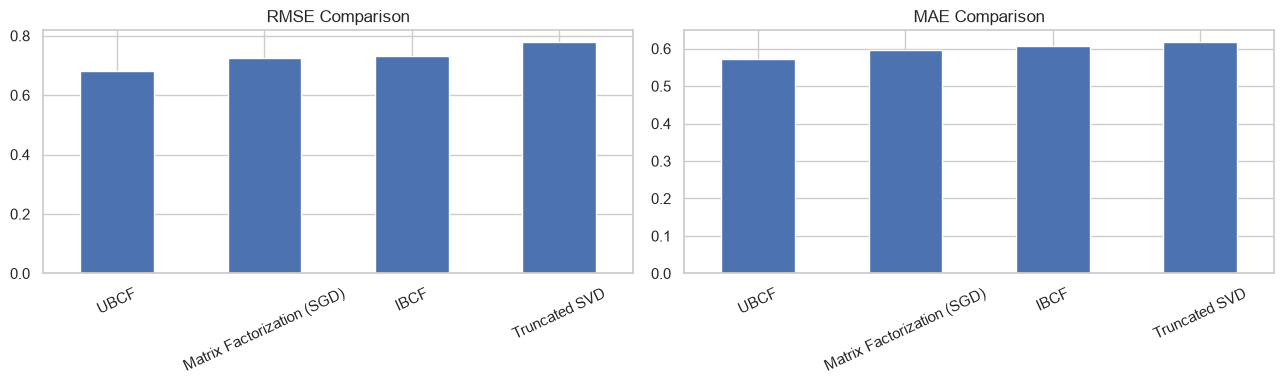

Best model by RMSE for this particular split: UBCF


In [12]:
results = []
for model_name, predictions in prediction_sets.items():
    results.append({
        "Model": model_name,
        "RMSE": np.sqrt(mean_squared_error(y_true, predictions)),
        "MAE": mean_absolute_error(y_true, predictions),
    })

performance = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
print("Model comparison on the same held-out test ratings (lower is better):")
display(performance.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
performance.set_index("Model")["RMSE"].plot(kind="bar", ax=axes[0])
axes[0].set_title("RMSE Comparison")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=25)

performance.set_index("Model")["MAE"].plot(kind="bar", ax=axes[1])
axes[1].set_title("MAE Comparison")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

best_model = performance.iloc[0]["Model"]
print(f"Best model by RMSE for this particular split: {best_model}")

## 14. Visualize predicted ratings

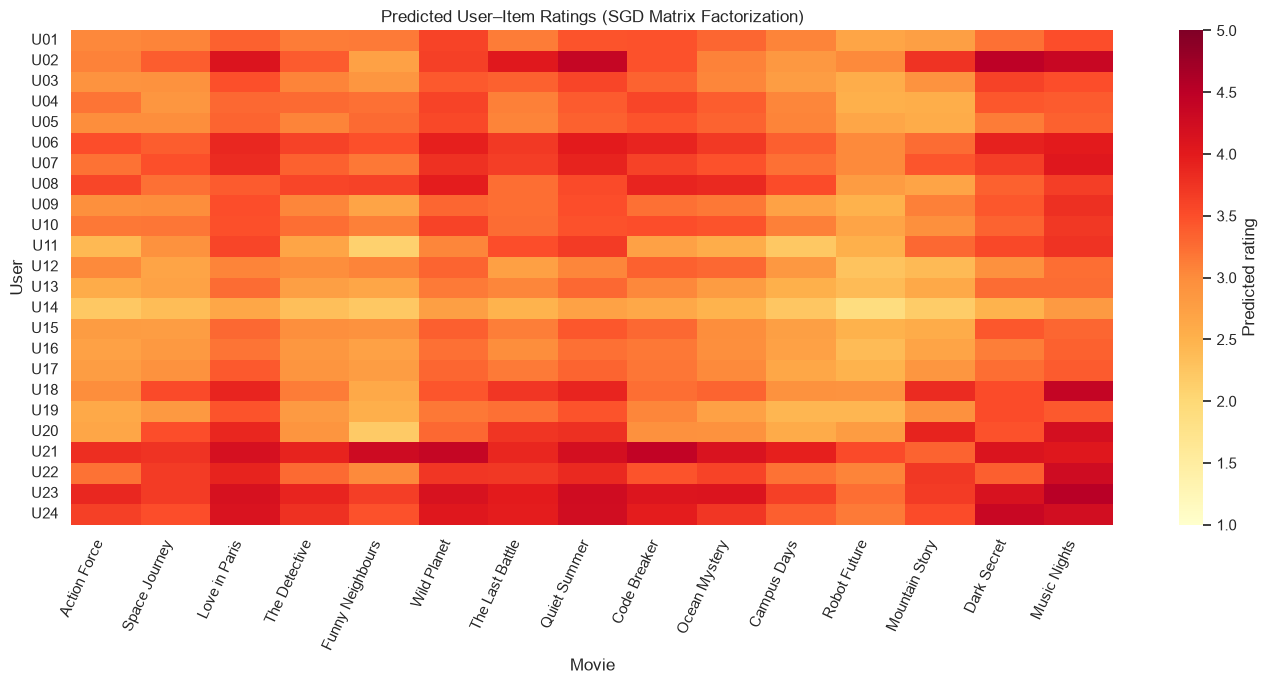

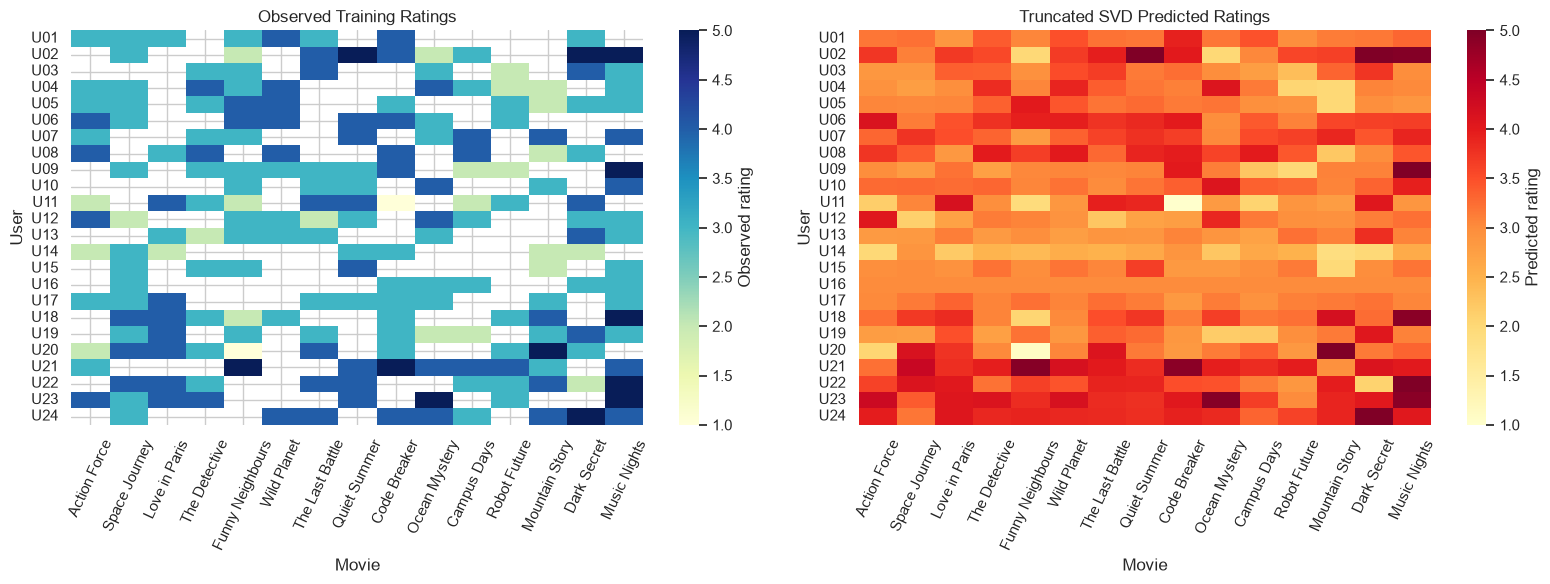

In [13]:
# Display the matrix of ratings predicted by the SGD Matrix Factorization model.
mf_prediction_matrix = mf_model.predict_matrix()

plt.figure(figsize=(14, 7))
sns.heatmap(mf_prediction_matrix, cmap="YlOrRd", vmin=1, vmax=5,
            cbar_kws={"label": "Predicted rating"})
plt.title("Predicted User–Item Ratings (SGD Matrix Factorization)")
plt.xlabel("Movie")
plt.ylabel("User")
plt.xticks(rotation=65, ha="right")
plt.tight_layout()
plt.show()

# Compare actual training ratings with SVD estimates for the same matrix.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(R_train.replace(0, np.nan), cmap="YlGnBu", vmin=1, vmax=5,
            ax=axes[0], cbar_kws={"label": "Observed rating"})
axes[0].set_title("Observed Training Ratings")
sns.heatmap(svd_prediction_matrix, cmap="YlOrRd", vmin=1, vmax=5,
            ax=axes[1], cbar_kws={"label": "Predicted rating"})
axes[1].set_title("Truncated SVD Predicted Ratings")
for ax in axes:
    ax.set_xlabel("Movie")
    ax.set_ylabel("User")
    ax.tick_params(axis="x", rotation=65)
plt.tight_layout()
plt.show()

## 15. Display recommendations from all four methods

In [14]:
def recommend_mf(model, known_matrix, user, n=5):
    unseen = known_matrix.columns[known_matrix.loc[user] == 0]
    rows = [(item, model.predict(user, item)) for item in unseen]
    return pd.DataFrame(rows, columns=["Item", "Predicted Rating"]).sort_values(
        "Predicted Rating", ascending=False
    ).head(n).reset_index(drop=True)

recommendation_comparison = {
    "UBCF": recommend_ubcf(example_user, n=5),
    "IBCF": recommend_ibcf(example_user, n=5),
    "Matrix Factorization": recommend_mf(mf_model, R_train, example_user, n=5),
    "Truncated SVD": recommend_from_matrix(svd_prediction_matrix, R_train, example_user, n=5),
}

for name, recs in recommendation_comparison.items():
    print(f"\n{name} recommendations for {example_user}")
    display(recs.round(3))


UBCF recommendations for U01


,Item,Predicted Rating
0,Music Nights,3.616
1,Quiet Summer,3.535
2,The Detective,3.510
3,Ocean Mystery,3.299
4,Campus Days,3.244



IBCF recommendations for U01


,Item,Predicted Rating
0,The Detective,3.586
1,Music Nights,3.395
2,Ocean Mystery,3.241
3,Campus Days,3.204
4,Quiet Summer,3.041



Matrix Factorization recommendations for U01


,Item,Predicted Rating
0,Music Nights,3.503
1,Quiet Summer,3.466
2,Ocean Mystery,3.305
3,The Detective,3.140
4,Campus Days,3.069



Truncated SVD recommendations for U01


,Item,Predicted Rating
0,Campus Days,3.478
1,The Detective,3.397
2,Music Nights,3.304
3,Ocean Mystery,3.178
4,Quiet Summer,3.175


## 16. Exercise 1 — Add a new user and generate recommendations

A new user can be supported by collecting a few ratings and finding existing users with similar preferences. The following helper performs a simple **user-based cold-start demonstration**: it compares the new user's ratings with existing users on co-rated movies, then predicts movies the new user has not rated.

In [15]:
def recommend_for_new_user(new_user_ratings, known_rating_matrix, n=5, k=5):
    """
    new_user_ratings: dict such as {"Action Force": 5, "Space Journey": 4}
    Uses overlap-based Pearson-style cosine similarity after mean-centering.
    """
    new_user_ratings = pd.Series(new_user_ratings, dtype=float)
    unknown_items = [item for item in known_rating_matrix.columns
                     if item not in new_user_ratings.index]
    new_mean = float(new_user_ratings.mean()) if len(new_user_ratings) else global_mean
    user_scores = {}

    for existing_user in known_rating_matrix.index:
        existing = known_rating_matrix.loc[existing_user]
        overlap = [item for item in new_user_ratings.index
                   if item in existing.index and existing[item] > 0]
        if len(overlap) < 2:
            continue

        a = new_user_ratings.loc[overlap].to_numpy(dtype=float)
        b = existing.loc[overlap].to_numpy(dtype=float)
        a = a - a.mean()
        b = b - b.mean()
        denominator = np.linalg.norm(a) * np.linalg.norm(b)
        similarity = float(np.dot(a, b) / denominator) if denominator > 0 else 0.0
        if similarity > 0:
            user_scores[existing_user] = similarity

    predictions = []
    for item in unknown_items:
        neighbors = [(u, sim) for u, sim in user_scores.items()
                     if known_rating_matrix.loc[u, item] > 0]
        neighbors = sorted(neighbors, key=lambda pair: pair[1], reverse=True)[:k]

        if neighbors:
            weights = np.array([sim for _, sim in neighbors], dtype=float)
            deviations = np.array([
                known_rating_matrix.loc[u, item] - user_means.loc[u]
                for u, _ in neighbors
            ], dtype=float)
            estimate = new_mean + np.dot(weights, deviations) / (np.abs(weights).sum() + 1e-12)
        else:
            estimate = float(item_means.loc[item])
        predictions.append((item, float(np.clip(estimate, 1, 5))))

    return (pd.DataFrame(predictions, columns=["Item", "Predicted Rating"])
            .sort_values("Predicted Rating", ascending=False).head(n).reset_index(drop=True))

new_user_ratings = {
    "Action Force": 5,
    "Space Journey": 4,
    "The Last Battle": 5,
    "Robot Future": 4,
}

print("New user ratings:")
display(pd.Series(new_user_ratings, name="Rating").to_frame())
print("Recommendations for the new user:")
display(recommend_for_new_user(new_user_ratings, R_train, n=5))

New user ratings:


,Rating
Action Force,5
Space Journey,4
The Last Battle,5
Robot Future,4


Recommendations for the new user:


,Item,Predicted Rating
0,Dark Secret,5.000000
1,Music Nights,5.000000
2,Quiet Summer,4.914583
3,Code Breaker,4.862698
4,Wild Planet,4.753175


## 17. Exercise 2 — Compare UBCF and IBCF recommendations

The next cell compares the top recommendations side by side for the selected user. Note that the two methods can produce different results because UBCF searches for similar **users**, whereas IBCF searches for similar **movies**.

In [16]:
ubcf_top = recommend_ubcf(example_user, n=5).assign(Method="UBCF")
ibcf_top = recommend_ibcf(example_user, n=5).assign(Method="IBCF")
comparison = pd.concat([ubcf_top, ibcf_top], ignore_index=True)
display(comparison[["Method", "Item", "Predicted Rating"]].round(3))

ubcf_items = set(ubcf_top["Item"])
ibcf_items = set(ibcf_top["Item"])
print("Common recommended movies:", sorted(ubcf_items.intersection(ibcf_items)))

,Method,Item,Predicted Rating
0,UBCF,Music Nights,3.616
1,UBCF,Quiet Summer,3.535
2,UBCF,The Detective,3.510
3,UBCF,Ocean Mystery,3.299
4,UBCF,Campus Days,3.244
5,IBCF,The Detective,3.586
6,IBCF,Music Nights,3.395
7,IBCF,Ocean Mystery,3.241
8,IBCF,Campus Days,3.204
9,IBCF,Quiet Summer,3.041


Common recommended movies: ['Campus Days', 'Music Nights', 'Ocean Mystery', 'Quiet Summer', 'The Detective']


## 18. Exercise 3 — Change the number of SVD components

A small number of components gives a simpler, more compressed representation. A larger number can preserve more variation but may also retain noise. The following experiment evaluates several component counts on the same held-out test set.

,Components,RMSE,MAE,Explained Variance
0,2,0.6801,0.5698,0.4122
1,4,0.7217,0.5794,0.6635
2,6,0.7463,0.5997,0.8117
3,8,0.7787,0.6176,0.8977
4,10,0.7408,0.5857,0.9565
5,12,0.7487,0.5910,0.9847


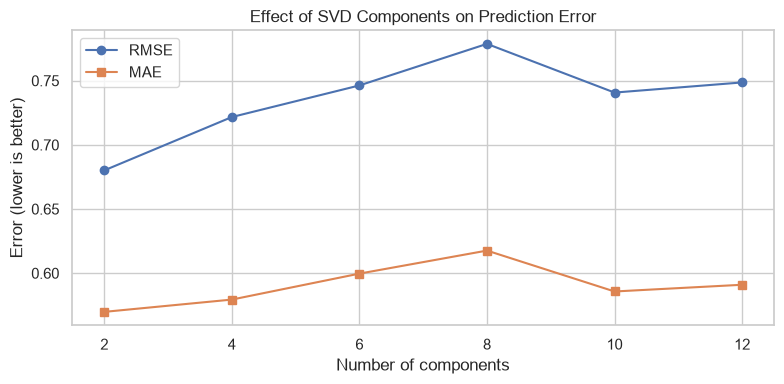

In [17]:
component_values = [2, 4, 6, 8, 10, 12]
svd_component_results = []
svd_models_by_k = {}

for n_comp in component_values:
    model_k, prediction_matrix_k = fit_svd_predictor(
        R_train, user_means, n_components=n_comp, random_state=RANDOM_STATE
    )
    predictions_k = np.array([
        prediction_matrix_k.loc[row.User, row.Item]
        for row in test_df.itertuples(index=False)
    ])
    svd_component_results.append({
        "Components": model_k.n_components,
        "RMSE": np.sqrt(mean_squared_error(y_true, predictions_k)),
        "MAE": mean_absolute_error(y_true, predictions_k),
        "Explained Variance": model_k.explained_variance_ratio_.sum(),
    })
    svd_models_by_k[model_k.n_components] = prediction_matrix_k

svd_component_results = pd.DataFrame(svd_component_results)
display(svd_component_results.round(4))

plt.figure(figsize=(8, 4))
plt.plot(svd_component_results["Components"], svd_component_results["RMSE"], marker="o", label="RMSE")
plt.plot(svd_component_results["Components"], svd_component_results["MAE"], marker="s", label="MAE")
plt.title("Effect of SVD Components on Prediction Error")
plt.xlabel("Number of components")
plt.ylabel("Error (lower is better)")
plt.legend()
plt.tight_layout()
plt.show()

## 19. Exercise 4 — Visualize predicted ratings using a heatmap

The heatmap below shows SVD predictions for the chosen user subset and movie set. Use the color scale to identify movies predicted to receive higher ratings.

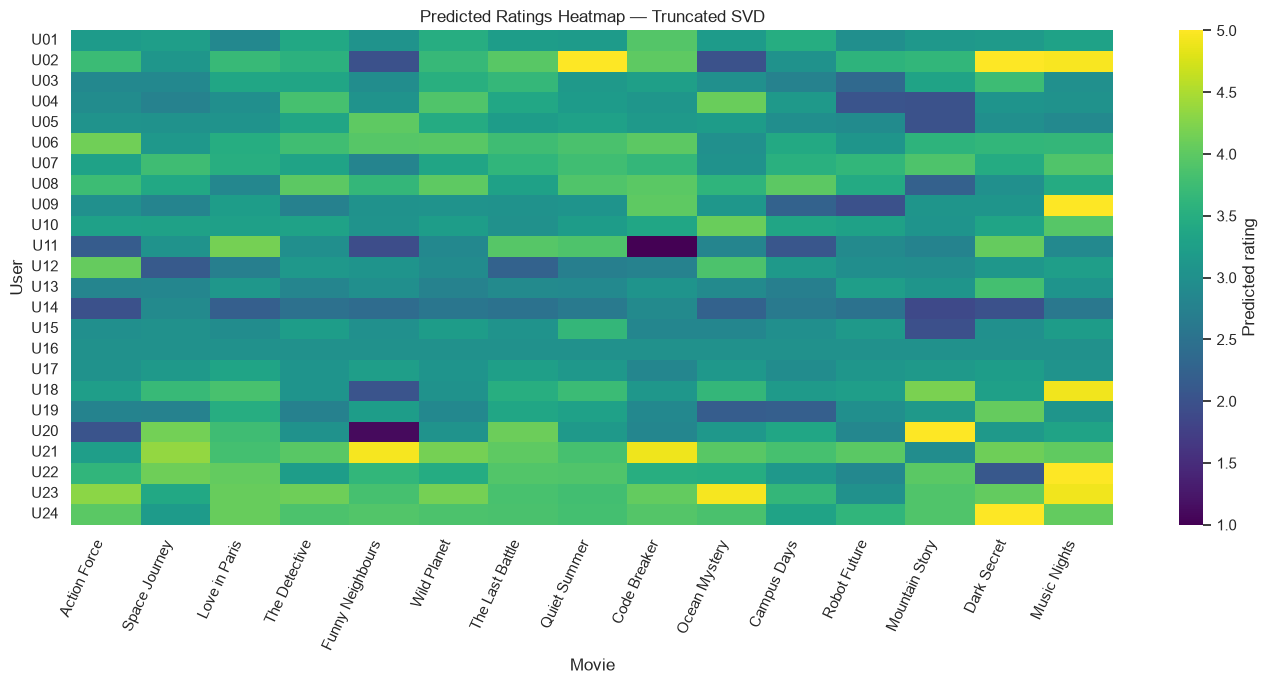

In [18]:
plt.figure(figsize=(14, 7))
sns.heatmap(svd_prediction_matrix, cmap="viridis", vmin=1, vmax=5,
            cbar_kws={"label": "Predicted rating"})
plt.title("Predicted Ratings Heatmap — Truncated SVD")
plt.xlabel("Movie")
plt.ylabel("User")
plt.xticks(rotation=65, ha="right")
plt.tight_layout()
plt.show()

## 20. Exercise 5 — Collaborative filtering vs content-based filtering

| Aspect | Collaborative filtering | Content-based filtering |
|---|---|---|
| Main information | User interactions/ratings | Item attributes such as genre, description, or keywords |
| How it recommends | Finds similar users or items, or learns latent factors | Finds items whose features resemble items the user liked |
| Need for item metadata | Not essential | Usually required |
| Strength | Can discover unexpected items based on collective behavior | Can recommend niche/new items when their attributes are known |
| Limitation | Cold-start and sparse-interaction problems | Can over-specialize and needs useful item features |

**Advantages of collaborative filtering:**
1. It does not require detailed movie descriptions or manually engineered item features.
2. It can discover hidden taste patterns from collective user behavior.
3. It can recommend items from different categories when users with similar tastes connect them.

**Limitations:** New users and new items have little interaction history (cold start), and sparse data can make similarity estimates unreliable. A hybrid system can combine collaborative and content-based signals.

## 21. Test cases and observations

| Test case | Expected result | Notebook evidence |
|---|---|---|
| Load rating dataset | Dataset created successfully | Section 3 |
| Create user–item matrix | Matrix created successfully | Section 5 |
| Compute user similarity | User similarity matrix generated | Section 7 |
| Compute item similarity | Item similarity matrix generated | Section 7 |
| Apply SVD | Reduced latent feature matrix generated | Section 11 |
| Display visualizations | Heatmaps and charts displayed | Sections 4, 5, 7, 13, 14, 19 |
| Generate recommendations | Ranked unseen movies displayed | Sections 8, 9, 11, 15, 16 |
| Compare model performance | RMSE/MAE comparison displayed | Section 13 |

### Observation
- The user–item rating matrix was created successfully.
- User and item cosine-similarity matrices were generated.
- UBCF and IBCF estimated missing ratings using neighboring users/items.
- SGD Matrix Factorization learned user and item latent factors from observed ratings.
- Truncated SVD generated a low-rank approximation of the mean-centered rating matrix.
- Heatmaps and metric charts helped compare rating patterns and recommendation behavior.
- Performance values depend on the dataset, train/test split, and model settings. Do not assume one technique will always be best.

### Result
UBCF, IBCF, SGD Matrix Factorization, and Truncated SVD were implemented on a sample movie-rating dataset. Recommendations were generated, visualized, and compared using RMSE and MAE on held-out ratings.

### Conclusion
This experiment demonstrated how collaborative-filtering methods use collective user behavior to predict unseen preferences. UBCF relies on similar users, IBCF relies on similar items, and latent-factor methods discover compact representations of users and items. Visualization and holdout evaluation provide complementary ways to inspect recommendation behavior and predictive performance.

## 22. Further practice

1. Change the random seed or dataset sparsity and observe how recommendations and errors change.
2. Change the number of neighbors (`k`) in UBCF and IBCF.
3. Change MF hyperparameters such as `n_factors`, `learning_rate`, `regularization`, and `n_epochs`.
4. Compare the models over several random train/test splits rather than relying on one split.
5. Replace the synthetic dataset with MovieLens and repeat the experiment.

**Important interpretation note:** Truncated SVD is itself a matrix-factorization technique. This notebook presents SGD-based latent-factor MF and Truncated SVD as two different practical approaches, not as mathematically unrelated families.